In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import matplotlib.colors as mcolors
from matplotlib.cm import ScalarMappable
from matplotlib.colors import ListedColormap
import geopandas as gpd

Got some good tips/advice from David Bangor and Plan to Implement Here

# Read the Fuel Data

In [2]:
# read distribution data
distribution_data = pd.read_csv('//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingInput/Distribution_2015-2024.csv',low_memory=False)
# filter distribution data
distribution_data = distribution_data[(distribution_data['time']<='2025')]
# create a date column
distribution_data['Date'] = pd.to_datetime(distribution_data['time']).dt.strftime('%Y-%m-%d')
# create a year column
distribution_data['Year'] = pd.to_datetime(distribution_data['time']).dt.year

In [3]:
# read circuit lengths
circuitlengths = pd.read_excel("//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingInput/Q1_2025-_HFRA_Conductor_SumStat_Circuit.xlsx")
# filter for OH only
circuitlengths = circuitlengths[circuitlengths['Conductor Type'].str.contains('OH',na=False)]
# filter for HFRA only
circuitlengths = circuitlengths[circuitlengths['HFRA Tier'].notna()]
# remove blank circuits
circuitlengths = circuitlengths[circuitlengths['Circuit Name'].notna()]
# capitalize circuit names
circuitlengths['Circuit Name'] = circuitlengths['Circuit Name'].str.upper()
circuitlengths_map = circuitlengths.groupby(['Circuit Name','Circuit FLOC'])['Circuit Miles'].sum().reset_index()

In [4]:
# read forecast distribution data
dist_df_forecast = pd.read_csv('//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingMidput/Dist_Forecasts_2025.csv', low_memory=False)
# make sure Date is date string of Datetime
dist_df_forecast['Date'] = pd.to_datetime(dist_df_forecast['Datetime']).dt.strftime('%Y-%m-%d')

In [5]:
# for forecast data, groupby Date, Circuit, take the mean of FuelsIndex_max_FPI2
dist_df_forecast_agg = dist_df_forecast.groupby(['Date', 'Circuit'])['FuelsIndex_max_FPI2'].mean().reset_index()
# # for forecast data, groupby Date, Circuit, take the max of FuelsIndex_max_FPI2
# dist_df_forecast_agg = dist_df_forecast.groupby(['Date', 'Circuit'])['FuelsIndex_max_FPI2'].max().reset_index()
# merge with circuit lengths
dist_df_forecast_agg = dist_df_forecast_agg.merge(circuitlengths_map, left_on='Circuit', right_on='Circuit Name', how='left')
# locate rows where Circuit Miles is NaN and Circuit contains ambercrest and change value to 32.7754002840092
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('AMBERCREST', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['AMBERCREST',32.7754002840092]
# locate rows where Circuit Miles is NaN and Circuit contains aventura and change value to 15.7032769637841
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('AVENTURA', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['AVENTURA',15.7032769637841]
# locate rows where Circuit Miles is NaN and Circuit contains birchim and change value to 46.34484383
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('BIRCHIM', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['BIRCHIM',46.34484383]
# locate rows where Circuit Miles is NaN and Circuit contains cafe and change value to 27.6402669615555
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('CAFE', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['CAFE',27.6402669615555]
# locate rows where Circuit Miles is NaN and Circuit contains canebrake and change value to 66.16859376
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('CANEBRAKE', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['CANEBRAKE',66.16859376]
# locate rows where Circuit Miles is NaN and Circuit contains casals and change value to 0.446999553409736
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('CASALS', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['CASALS',0.446999553409736]
# locate rows where Circuit Miles is NaN and Circuit contains coachella and change value to 6.590021052
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('COACHELLA', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['COACHELLA',6.590021052]
# locate rows where circuit miles is NaN and circuit contains energy and change value to 32.37798311
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('ENERGY', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['ENERGY',32.37798311]
# locate rows where circuit miles is NaN and circuit contains fingal and change value to 36.6548594697613
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('FINGAL', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['FINGAL',36.6548594697613]
# locate rows where circuit miles is NaN and circuit contains guitar and change value to 42.2491638220717
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('GUITAR', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['GUITAR',42.2491638220717]
# locate rows where circuit miles is NaN and circuit contains huckleberry and change value to 25.4840533042463
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('HUCKLEBERRY', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['HUCKLEBERRY',25.4840533042463]
# locate rows where circuit miles is NaN and circuit contains Kinsey and change value to 38.2093922
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('KINSEY', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['KINSEY',38.2093922]
# locate rows where circuit miles is NaN and circuit contains Penstock and change value to 50.90351311
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('PENSTOCK', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['PENSTOCK',50.90351311]
# locate rows where circuit miles is NaN and circuit contains Shovel and change value to 47.51064986
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('SHOVEL', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['SHOVEL',47.51064986]
# locate rows where circuit miles is NaN and circuit contains Tejon and change value to 57.8330462
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('TEJON', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['TEJON',57.8330462]
# locate rows where circuit miles is NaN and circuit contains Toll and change value to 8.228283341
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('TOLL', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['TOLL',8.228283341]
# locate rows where circuit miles is NaN and circuit contains Sutt and change value to 16.8635623
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('SUTT', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['SUTT',16.8635623]
# locate rows where circuit miles is NaN and circuit contains POPPET FLATS and change value to 31.30335437
dist_df_forecast_agg.loc[dist_df_forecast_agg['Circuit'].str.contains('POPPET FLATS', na=False) & dist_df_forecast_agg['Circuit Miles'].isna(), ['Circuit Name','Circuit Miles']] = ['POPPET FLATS',31.30335437]
# sort values by Date and Circuit Name and FuelsIndex_max_FPI2 descending
dist_df_forecast_agg = dist_df_forecast_agg.sort_values(by=['Date', 'Circuit Name', 'FuelsIndex_max_FPI2'], ascending=[True, True, False])
# # drop duplicate Date and Circuit Name, keep first one
dist_df_forecast_agg = dist_df_forecast_agg.drop_duplicates(subset=['Date', 'Circuit Name'], keep='first')

# Read the Ignition Data

In [6]:
# read ignition data
ignitions = pd.read_excel("//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingInput/Ignition_Safari_Connection.xlsx")
# rename columns 
ignitions = ignitions.rename(columns={'Date/Time':'Date','Circuit Name':'Circuit_Name','Circuit ID':'Circuit_ID','Event ID':'Event_ID'})
# get year column
ignitions['Year'] = pd.to_datetime(ignitions['Date']).dt.year
# keep only SCE involved ignitions
ignitions = ignitions[ignitions['SCE Involved'].str.contains('yes|inconclusive',case=False,na=False)]
# keep only reportable ignitions
ignitions = ignitions[ignitions['CPUC Reportable']==1]
# for Status, ignore the ones that say open
ignitions = ignitions[~ignitions['Status'].str.contains('open', case=False, na=False)]
# keep only HFRA ignitions
ignitions = ignitions[ignitions['HFRA'].str.contains('T2|T3',na=False)]
# loc row where circuit name has 'banducci' and change Circuit_ID to ET-02156
ignitions.loc[ignitions['Circuit_Name'].str.contains('banducci', case=False, na=False), 'Circuit_ID'] = 'ET-02156'
# change date format
ignitions['Date'] = pd.to_datetime(ignitions['Date']).dt.strftime('%Y-%m-%d')
# from 2015 onward
ignitions = ignitions[ignitions['Year'] >= 2015]
# # before August 1 2025
# ignitions = ignitions[ignitions['Date'] < '2025-08-01']
# group by Year and get count of ignitions
ignitions = ignitions.groupby('Year').agg({'Event_ID': 'count'}).reset_index()

In [7]:
# determine fuel_var to use
ads_agg = 'mean_max'
# change fuel_var to a different aggregation
ads_agg = 'max_max'
fuel_var = f'{ads_agg}_fpi_2.0_tdd_fuels_index'
ads_agg2 = 'max_max'
wind_var = f'{ads_agg2}_lfpw_using_dew_point_depression'
# create a copy of the distribution data
res_df = distribution_data[['Date','Year','id',fuel_var,]].copy()
# rename id column to Circuit Name
res_df.rename(columns={'id': 'Circuit Name'}, inplace=True)
# # create another dataframe for the forecast data
# res_df_forecast = dist_df_forecast_agg[['Date', 'Circuit', 'FuelsIndex_max_FPI2',]].copy()
# # create a year column
# res_df_forecast['Year'] = pd.to_datetime(res_df_forecast['Date']).dt.year
# # rename the column
# res_df_forecast.rename(columns={'Circuit': 'Circuit Name', 'FuelsIndex_max_FPI2': fuel_var,}, inplace=True)
# print(res_df_forecast.columns)
# print(res_df.columns)
# # concat the dataframes
# res_df = pd.concat([res_df, res_df_forecast], ignore_index=True)
# # sort by Circuit Name and Date
# res_df.sort_values(by=['Circuit Name', 'Date'], inplace=True)
# create a new column called adjusted fuel_var
# use the rolling mean of the fuel_var over a 14-day window
res_df[f'{fuel_var}_rolling'] = res_df[fuel_var].rolling(window=14, min_periods=1).mean()
# merge with circuitlengths_map
res_df = res_df.merge(circuitlengths_map, on='Circuit Name', how='left')
# # filter for only 2019-2024 data
# res_df = res_df[res_df['Year'].between(2017, 2024)]
# drop the na Circuit Miles
res_df = res_df[res_df['Circuit Miles'].notna()]
# categorize fuel_var into above and below 0.7
fuel_val = 0.85
# create a second fuel_val for accounting wind
fuel_val2 = fuel_val
wind_val = 0
res_df['Fuel Category'] = np.where((res_df[fuel_var] >= fuel_val), f'High', 'Low')
# # save a temporary file for Dashboard to use
# res_df.to_csv("CircuitLevelData/CircuitData_Dashboard.csv",index=False)
# set fuel category based on rolling mean
res_df['Fuel Category 2'] = np.where((res_df[f'{fuel_var}_rolling'] >= fuel_val), f'High', 'Low')
# aggregate by Year and Fuel Category
res_df = res_df.groupby(['Year', 'Fuel Category']).agg({'Circuit Miles': 'sum'}).reset_index()
# only keep the high fuel category
res_df = res_df[res_df['Fuel Category'] == 'High']
# merge with ignitions data
res_df = res_df.merge(ignitions, on='Year', how='left')
# locate where Year is 2019 and change Event_ID to 41
res_df.loc[res_df['Year'] == 2019, 'Event_ID'] = 41
# locate where Year is 2020 and change Event_ID to 51
res_df.loc[res_df['Year'] == 2020, 'Event_ID'] = 51
# locate where Year is 2024 and change Event_ID to 48
res_df.loc[res_df['Year'] == 2024, 'Event_ID'] = 48
# # locate where year is 2025 and change event_id to 21
# res_df.loc[res_df['Year'] == 2025, 'Event_ID'] = 21
# get the ratio by dividing Event_ID by Circuit Miles
res_df['Ignition Ratio'] = res_df['Event_ID'] / res_df['Circuit Miles']

# create another dataframe for the forecast data
res_df_forecast = dist_df_forecast_agg[['Date', 'Circuit', 'FuelsIndex_max_FPI2', 'Circuit Miles']].copy()
# create a year column
res_df_forecast['Year'] = pd.to_datetime(res_df_forecast['Date']).dt.year
# categorize fuel_var into above and below 0.7
res_df_forecast['Fuel Category'] = np.where((res_df_forecast['FuelsIndex_max_FPI2'] >= fuel_val), f'High', 'Low')
# aggregate by Year and Fuel Category
res_df_forecast = res_df_forecast.groupby(['Year', 'Fuel Category']).agg({'Circuit Miles': 'sum',}).reset_index()
# filter for High fuel category
res_df_forecast = res_df_forecast[res_df_forecast['Fuel Category'] == 'High']
# merge with ignitions data
res_df_forecast = res_df_forecast.merge(ignitions, on='Year', how='left')
# get the ratio by dividing Event_ID by Circuit Miles
res_df_forecast['Ignition Ratio'] = res_df_forecast['Event_ID'] / res_df_forecast['Circuit Miles']

# combine the two dataframes
res_df = pd.concat([res_df, res_df_forecast], ignore_index=True)
res_df

,Year,Fuel Category,Circuit Miles,Event_ID,Ignition Ratio
0,2015,High,1.224543e+06,46,0.000038
1,2016,High,1.514441e+06,42,0.000028
2,2017,High,1.289938e+06,34,0.000026
3,2018,High,1.426052e+06,37,0.000026
4,2019,High,1.277067e+06,41,0.000032
5,2020,High,1.413993e+06,51,0.000036
6,2021,High,1.681770e+06,48,0.000029
7,2022,High,1.325925e+06,41,0.000031
8,2023,High,5.547501e+05,19,0.000034
9,2024,High,1.321481e+06,48,0.000036


In [8]:
# create a result table
table = []
for yr in range(2020, 2027):
    start, end = yr-5, yr-1
    # filter the data for the last 5 years
    filtered_data = res_df[(res_df['Year'] >= start) & (res_df['Year'] <= end)]
    # assign weights to first, second and third year
    weights = [0.1, 0.2, 0.7]
    # using unweighted version
    weights = [1/5, 1/5, 1/5, 1/5, 1/5]
    filtered_data['weights'] = weights
    # calculate the weighted average of Ignition Ratio
    weighted_avg = (filtered_data['Ignition Ratio'] * filtered_data['weights']).sum() / filtered_data['weights'].sum()
    target = weighted_avg
    # get the standard deviation of Ignition Ratio and multiply by 2 to get bound
    bound = filtered_data['Ignition Ratio'].std() * 2
    # get p80 by adding the bound to the ratio
    p80 = target + bound
    # get p20 by subtracting the bound from the ratio
    p20 = target - bound
    # get the actual ratio for the current year
    actual = res_df[res_df['Year'] == yr]['Ignition Ratio'].values
    if actual.size == 0:
        actual = [0]
    # append the result to the table
    table.append({
        'Year': yr,
        'Actual': actual[0],
        'P20': p20, 
        'Target': target,
        'P80': p80,
        'Bound': bound
    })
# convert the table to a DataFrame
result_table = pd.DataFrame(table)
result_table

C:\Users\tongcj\AppData\Local\Temp\ipykernel_27460\3603921579.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data['weights'] = weights
C:\Users\tongcj\AppData\Local\Temp\ipykernel_27460\3603921579.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_data['weights'] = weights
C:\Users\tongcj\AppData\Local\Temp\ipykernel_27460\3603921579.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value ins

,Year,Actual,P20,Target,P80,Bound
0,2020,0.000036,0.000020,0.000030,0.000040,0.000010
1,2021,0.000029,0.000021,0.000030,0.000038,0.000009
2,2022,0.000031,0.000021,0.000030,0.000038,0.000009
3,2023,0.000034,0.000023,0.000031,0.000038,0.000008
4,2024,0.000036,0.000027,0.000032,0.000038,0.000006
5,2025,0.000043,0.000026,0.000033,0.000040,0.000007
6,2026,0.000000,0.000023,0.000035,0.000046,0.000011


In [9]:
# get month over month performance for circuit
ignitions_2025 = pd.read_excel("//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingInput/Ignition_Safari_Connection.xlsx")
# rename columns 
ignitions_2025 = ignitions_2025.rename(columns={'Date/Time':'Date','Circuit Name':'Circuit_Name','Circuit ID':'Circuit_ID','Event ID':'Event_ID'})
# get year column
ignitions_2025['Year'] = pd.to_datetime(ignitions_2025['Date']).dt.year
# keep only 2025 in Year
ignitions_2025 = ignitions_2025[ignitions_2025['Year'] == 2025]
# get month column
ignitions_2025['Month'] = pd.to_datetime(ignitions_2025['Date']).dt.month
# keep only SCE involved ignitions
ignitions_2025 = ignitions_2025[ignitions_2025['SCE Involved'].str.contains('yes|inconclusive',case=False,na=False)]
# keep only reportable ignitions
ignitions_2025 = ignitions_2025[ignitions_2025['CPUC Reportable']==1]
# keep only HFRA ignitions
ignitions_2025 = ignitions_2025[ignitions_2025['HFRA'].str.contains('T2|T3',na=False)]
# loc row where circuit name has 'banducci' and change Circuit_ID to ET-02156
ignitions_2025.loc[ignitions_2025['Circuit_Name'].str.contains('banducci', case=False, na=False), 'Circuit_ID'] = 'ET-02156'
# group by month
ignitions_2025_grouped = ignitions_2025.groupby(['Month']).size().reset_index(name='Counts')
# create a cumsum
ignitions_2025_grouped['CumsumCounts'] = ignitions_2025_grouped['Counts'].cumsum()

# create a copy of the aggreagated forecast file
dist_df_forecast_agg_cp = dist_df_forecast_agg.copy()
# create a month column
dist_df_forecast_agg_cp['Month'] = pd.to_datetime(dist_df_forecast_agg_cp['Date']).dt.month
# categorize fuel column
dist_df_forecast_agg_cp['Fuel_Category'] = np.where(dist_df_forecast_agg_cp['FuelsIndex_max_FPI2'] >= fuel_val, 'High', 'Low')
# group by fuel category
dist_df_forecast_agg_cp = dist_df_forecast_agg_cp.groupby(['Month','Fuel_Category']).agg({'Circuit Miles':'sum'}).reset_index()
# keep only High Category
dist_df_forecast_agg_cp = dist_df_forecast_agg_cp[dist_df_forecast_agg_cp['Fuel_Category'] == 'High']

# merge
ignitions_2025_grouped = ignitions_2025_grouped.merge(dist_df_forecast_agg_cp, on='Month', how='left')
# for miles, fillna with 0
ignitions_2025_grouped['Circuit Miles'] = ignitions_2025_grouped['Circuit Miles'].fillna(0)
# create a cumsum miles column
ignitions_2025_grouped['CumsumMiles'] = ignitions_2025_grouped['Circuit Miles'].cumsum()
# calculate cum sum rate
ignitions_2025_grouped['CumsumRate'] = ignitions_2025_grouped['CumsumCounts'] / ignitions_2025_grouped['CumsumMiles']
ignitions_2025_grouped

,Month,Counts,CumsumCounts,Fuel_Category,Circuit Miles,CumsumMiles,CumsumRate
0,1,4,4,High,13502.041819,13502.041819,0.000296
1,2,2,6,NaN,0.000000,13502.041819,0.000444
2,3,1,7,NaN,0.000000,13502.041819,0.000518
3,4,1,8,NaN,0.000000,13502.041819,0.000593
4,5,3,11,High,804.977461,14307.019281,0.000769
5,6,6,17,High,67928.497956,82235.517236,0.000207
6,7,3,20,High,173091.084684,255326.601920,0.000078
7,8,6,26,High,285264.519125,540591.121046,0.000048
8,9,2,28,High,87812.074427,628403.195473,0.000045


## Option 1: Use 0.85 as Cutoff Without Using Rolling Fuel Mean

In [28]:
# read ignition data
ignitions = pd.read_excel("//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingInput/Ignition_Safari_Connection.xlsx")
# rename columns 
ignitions = ignitions.rename(columns={'Date/Time':'Date','Circuit Name':'Circuit_Name','Circuit ID':'Circuit_ID','Event ID':'Event_ID'})
# get year column
ignitions['Year'] = pd.to_datetime(ignitions['Date']).dt.year
# keep only SCE involved ignitions
ignitions = ignitions[ignitions['SCE Involved'].str.contains('yes|inconclusive',case=False,na=False)]
# keep only reportable ignitions
ignitions = ignitions[ignitions['CPUC Reportable']==1]
# for Status, ignore the ones that say open
ignitions = ignitions[~ignitions['Status'].str.contains('open', case=False, na=False)]
# keep only HFRA ignitions
ignitions = ignitions[ignitions['HFRA'].str.contains('T2|T3',na=False)]
# loc row where circuit name has 'banducci' and change Circuit_ID to ET-02156
ignitions.loc[ignitions['Circuit_Name'].str.contains('banducci', case=False, na=False), 'Circuit_ID'] = 'ET-02156'
# change date format
ignitions['Date'] = pd.to_datetime(ignitions['Date']).dt.strftime('%Y-%m-%d')
# from 2015 onward
ignitions = ignitions[ignitions['Year'] >= 2015]
# # before August 1 2025
# ignitions = ignitions[ignitions['Date'] < '2025-08-01']
# group by Year and get count of ignitions
ignitions = ignitions.groupby('Year').agg({'Event_ID': 'count'}).reset_index()

In [34]:
# determine fuel_var to use
ads_agg = 'mean_max'
ads_agg = 'mean_p90' #### APPLY CHANGE HERE TO CHANGE THE GRAPHS FOR DAVID
fuel_var = f'{ads_agg}_fpi_2.0_tdd_fuels_index'
ads_agg2 = 'max_max'
wind_var = f'{ads_agg2}_lfpw_using_dew_point_depression'
# create a copy of the distribution data
res_df = distribution_data[['Date','Year','id',fuel_var,]].copy()
# rename id column to Circuit Name
res_df.rename(columns={'id': 'Circuit Name'}, inplace=True)
# # create another dataframe for the forecast data
# res_df_forecast = dist_df_forecast_agg[['Date', 'Circuit', 'FuelsIndex_max_FPI2',]].copy()
# # create a year column
# res_df_forecast['Year'] = pd.to_datetime(res_df_forecast['Date']).dt.year
# # rename the column
# res_df_forecast.rename(columns={'Circuit': 'Circuit Name', 'FuelsIndex_max_FPI2': fuel_var,}, inplace=True)
# print(res_df_forecast.columns)
# print(res_df.columns)
# # concat the dataframes
# res_df = pd.concat([res_df, res_df_forecast], ignore_index=True)
# # sort by Circuit Name and Date
# res_df.sort_values(by=['Circuit Name', 'Date'], inplace=True)
# create a new column called adjusted fuel_var
# use the rolling mean of the fuel_var over a 14-day window
res_df[f'{fuel_var}_rolling'] = res_df[fuel_var].rolling(window=14, min_periods=1).mean()
# merge with circuitlengths_map
res_df = res_df.merge(circuitlengths_map, on='Circuit Name', how='left')
# # filter for only 2019-2024 data
# res_df = res_df[res_df['Year'].between(2017, 2024)]
# drop the na Circuit Miles
res_df = res_df[res_df['Circuit Miles'].notna()]
# categorize fuel_var into above and below 0.7
fuel_val = 0.85
# create a second fuel_val for accounting wind
fuel_val2 = fuel_val
wind_val = 0
res_df['Fuel Category'] = np.where((res_df[fuel_var] >= fuel_val), f'High', 'Low')
# # save a temporary file for Dashboard to use
# res_df.to_csv("CircuitLevelData/CircuitData_Dashboard.csv",index=False)
# set fuel category based on rolling mean
res_df['Fuel Category 2'] = np.where((res_df[f'{fuel_var}_rolling'] >= fuel_val), f'High', 'Low')
# aggregate by Year and Fuel Category
res_df = res_df.groupby(['Year', 'Fuel Category']).agg({'Circuit Miles': 'sum'}).reset_index()
# only keep the high fuel category
res_df = res_df[res_df['Fuel Category'] == 'High']
# merge with ignitions data
res_df = res_df.merge(ignitions, on='Year', how='left')
# # locate where Year is 2019 and change Event_ID to 41
# res_df.loc[res_df['Year'] == 2019, 'Event_ID'] = 41
# locate where Year is 2020 and change Event_ID to 51
res_df.loc[res_df['Year'] == 2020, 'Event_ID'] = 51
# locate where Year is 2024 and change Event_ID to 48
res_df.loc[res_df['Year'] == 2024, 'Event_ID'] = 48
# # locate where year is 2025 and change event_id to 26
# res_df.loc[res_df['Year'] == 2025, 'Event_ID'] = 26
# get the ratio by dividing Event_ID by Circuit Miles
res_df['Ignition Ratio'] = res_df['Event_ID'] / res_df['Circuit Miles']

# create another dataframe for the forecast data
res_df_forecast = dist_df_forecast_agg[['Date', 'Circuit', 'FuelsIndex_max_FPI2', 'Circuit Miles']].copy()
# create a year column
res_df_forecast['Year'] = pd.to_datetime(res_df_forecast['Date']).dt.year
# categorize fuel_var into above and below 0.7
res_df_forecast['Fuel Category'] = np.where((res_df_forecast['FuelsIndex_max_FPI2'] >= fuel_val), f'High', 'Low')
# aggregate by Year and Fuel Category
res_df_forecast = res_df_forecast.groupby(['Year', 'Fuel Category']).agg({'Circuit Miles': 'sum',}).reset_index()
# filter for High fuel category
res_df_forecast = res_df_forecast[res_df_forecast['Fuel Category'] == 'High']
# merge with ignitions data
res_df_forecast = res_df_forecast.merge(ignitions, on='Year', how='left')
# locate where Year is 2025 and change Event_ID to 26
res_df_forecast.loc[res_df_forecast['Year'] == 2025, 'Event_ID'] = 26
# get the ratio by dividing Event_ID by Circuit Miles
res_df_forecast['Ignition Ratio'] = res_df_forecast['Event_ID'] / res_df_forecast['Circuit Miles']

# combine the two dataframes
res_df = pd.concat([res_df, res_df_forecast], ignore_index=True)
res_df

,Year,Fuel Category,Circuit Miles,Incident ID,Parent ID,Event_ID,Title,Date,Status,Engineer,...,All Circuits Involved,All Structures Involved,notification,Work Order,Created,Assigned,Review Start,Completed,Root Cause FLOC,Ignition Ratio
0,2015,High,7.917275e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaT,NaT,NaT,NaT,NaN,NaN
1,2016,High,1.189684e+06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaT,NaT,NaT,NaT,NaN,NaN
2,2017,High,8.806675e+05,56854.0,NaN,243.0,FIPA_2017_0113_1105,2017-01-13,Desktop Investigation - Complete,NaN,...,SAUNDERS,OH-220632S,NaN,NaN,2024-01-29 16:01:00,2024-03-08 07:55:00,NaT,2024-03-08 07:55:00,NaN,0.000276
3,2017,High,8.806675e+05,56862.0,NaN,251.0,FIPA_2017_0315_1323,2017-03-15,Desktop Investigation - Complete,NaN,...,OAK GLEN,OH-2326555E,NaN,NaN,2024-01-29 16:01:00,2024-03-08 07:55:00,NaT,2024-03-08 07:55:00,NaN,0.000285
4,2017,High,8.806675e+05,56863.0,NaN,252.0,FIPA_2017_0317_1714,2017-03-17,Desktop Investigation - Complete,NaN,...,HUCKLEBERRY,OH-4493863E,NaN,NaN,2024-01-29 16:01:00,2024-03-08 07:55:00,NaT,2024-03-08 07:55:00,NaN,0.000286
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314,2024,High,1.039994e+06,58396.0,NaN,48.0,FIPA_2024_1115_1516,2024-11-15,Desktop Investigation - Complete,Phillip Melendez,...,Concepcion,"UG-5768685, UG-5438398",414332385.0,904645830.0,2024-11-21 06:33:00,2024-11-21 08:43:00,2024-11-25 17:02:00,2024-12-04 08:58:00,UG-5438398,0.000046
315,2024,High,1.039994e+06,59278.0,NaN,48.0,FIPA_2024_1201_0933,2024-12-01,Desktop Investigation - Complete,Ricardo Melgar,...,Calgrove,OH-1693555E,414352554.0,904658945.0,2024-12-12 07:26:00,2024-12-12 08:50:00,2024-12-12 13:45:00,2024-12-18 08:16:00,OH-1693555E,0.000046
316,2024,High,1.039994e+06,59467.0,NaN,48.0,FIPA_2024_1204_0354,2024-12-04,Field Visit - Complete,Joanne Garong,...,Lakeview-Moval,OH-1923171E,NaN,NaN,2024-12-18 16:23:00,2024-12-19 08:48:00,2024-12-20 12:41:00,2025-01-22 09:06:00,OH-4224539E,0.000046
317,2024,High,1.039994e+06,60021.0,14801.0,48.0,FIPA_2024_1224_1659,2024-12-24,Desktop Investigation - Complete,Joanne Garong,...,Duffer,"OH-1523404E, OH-4797578E",414395564.0,904690360.0,2024-12-30 11:13:00,2025-01-02 08:41:00,2025-01-03 15:42:00,2025-01-08 10:02:00,OH-4797578E,0.000046


### Creating Ignition Distribution Matrix

In [35]:
# get the ignition data
# read list of ignitions with FCZ mapped
ignitions = pd.read_excel("//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingInput/Ignition_Safari_Connection.xlsx")
# rename columns 
ignitions = ignitions.rename(columns={'Date/Time':'Date','Circuit Name':'Circuit_Name','Circuit ID':'Circuit_ID','Event ID':'Event_ID'})
# get year column
ignitions['Year'] = pd.to_datetime(ignitions['Date']).dt.year
# keep only SCE involved ignitions
ignitions = ignitions[ignitions['SCE Involved'].str.contains('yes|inconclusive',case=False,na=False)]
# ignore rows that have open status
ignitions = ignitions[~ignitions['Status'].str.contains('open', case=False, na=False)]
# keep only reportable ignitions
ignitions = ignitions[ignitions['CPUC Reportable']==1]
# keep only HFRA ignitions
ignitions = ignitions[ignitions['HFRA'].str.contains('T2|T3',na=False)]
# loc row where circuit name has 'banducci' and change Circuit_ID to ET-02156
ignitions.loc[ignitions['Circuit_Name'].str.contains('banducci', case=False, na=False), 'Circuit_ID'] = 'ET-02156'
# change date format
ignitions['Date'] = pd.to_datetime(ignitions['Date']).dt.strftime('%Y-%m-%d')
# from 2017 onward
ignitions = ignitions[ignitions['Year'] >= 2017]
# before 2025
ignitions = ignitions[ignitions['Year'] < 2025]

# group by Date and Circuit_ID
ignitions_count_agg = ignitions.groupby(['Date','Circuit_ID']).agg({'Event_ID': 'count',}).reset_index().rename(columns={'Event_ID': 'Ignition_Count', 'Circuit_ID':'Circuit FLOC'})
ignitions_count_agg

,Date,Circuit FLOC,Ignition_Count
0,2017-01-13,ED-15922,1
1,2017-03-15,ED-12960,1
2,2017-03-17,ED-08795,1
3,2017-04-16,ED-13791,1
4,2017-04-23,ED-08795,1
...,...,...,...
307,2024-11-09,ED-14005,1
308,2024-11-15,ED-03890,1
309,2024-12-01,ED-02674,1
310,2024-12-04,ET-00069,1


In [36]:
# create a copy of ignitions_agg data 
ignitions_agg = ignitions_count_agg.copy()
# map Circuit FLOC to Circuit Name
ignitions_agg = pd.merge(ignitions_agg, circuitlengths_map, on='Circuit FLOC', how='left', validate='m:1')
# reread circuit lengths file
circuitlengths2 = pd.read_excel("//sce.eix.com/workgroup/SPE_DSA/Charles/IgnitionGoalSettingInput/Q1_2025-_HFRA_Conductor_SumStat_Circuit.xlsx")
# filter only for ones where ignitions_agg Circuit Name is Null
circuitlengths2 = circuitlengths2[circuitlengths2['Circuit FLOC'].isin(ignitions_agg[ignitions_agg['Circuit Name'].isna()]['Circuit FLOC'].unique())]
circuitlengths2_hfra = circuitlengths2[circuitlengths2['HFRA Tier'].notna()]
# group by Circuit FLOC and Circuit Name, summing Circuit Miles
circuitlengths2_hfra = circuitlengths2_hfra.groupby(['Circuit FLOC', 'Circuit Name'])['Circuit Miles'].sum().reset_index()
circuitlengths2_nonhfra = circuitlengths2[circuitlengths2['HFRA Tier'].isna()]
# group by Circuit FLOC and Circuit Name, summing Circuit Miles
circuitlengths2_nonhfra = circuitlengths2_nonhfra.groupby(['Circuit FLOC', 'Circuit Name'])['Circuit Miles'].sum().reset_index()
# merge circuitlengths2_hfra with ignitions_agg
ignitions_agg = pd.merge(ignitions_agg, circuitlengths2_hfra, on='Circuit FLOC', how='left', validate='m:1', suffixes=('', '_y'))
# merge circuitlengths2_nonhfra with ignitions_agg
ignitions_agg = pd.merge(ignitions_agg, circuitlengths2_nonhfra, on='Circuit FLOC', how='left', validate='m:1', suffixes=('', '_nonhfra'))
# fill NaN values in Circuit Name with Circuit Name_y or Circuit Name_nonhfra
ignitions_agg['Circuit Name'] = ignitions_agg['Circuit Name'].fillna(ignitions_agg['Circuit Name_y']).fillna(ignitions_agg['Circuit Name_nonhfra'])
# fill NaN values in Circuit Miles with Circuit Miles_y or Circuit Miles_nonhfra
ignitions_agg['Circuit Miles'] = ignitions_agg['Circuit Miles'].fillna(ignitions_agg['Circuit Miles_y']).fillna(ignitions_agg['Circuit Miles_nonhfra'])
# drop unnecessary columns
ignitions_agg = ignitions_agg.drop(columns=['Circuit Name_y', 'Circuit Miles_y', 'Circuit Name_nonhfra', 'Circuit Miles_nonhfra'])
# get circuit data
all_circuit_data = distribution_data[['Date','id', fuel_var]].copy()
# create a rolling mean column
all_circuit_data[f'{fuel_var}_rolling'] = all_circuit_data[fuel_var].rolling(window=14, min_periods=1).mean()
# rename columns
all_circuit_data = all_circuit_data.rename(columns={
    'id': 'Circuit Name',
    'time': 'Date',
})
# # make sure Circuit Name is uppercase
all_circuit_data['Circuit Name'] = all_circuit_data['Circuit Name'].str.upper()
# split the Circuit Name from _
# make sure Date is in the correct format
all_circuit_data['Date'] = pd.to_datetime(all_circuit_data['Date']).dt.strftime('%Y-%m-%d')
# keep only ones before 2025
all_circuit_data = all_circuit_data[all_circuit_data['Date'] < '2025-01-01']
# split Circuit Name by _ and keep the first part
all_circuit_data['Circuit Name'] = all_circuit_data['Circuit Name'].str.split('_').str[0]
# drop duplicates
all_circuit_data = all_circuit_data.drop_duplicates(subset=['Circuit Name', 'Date'])
# # read forecast circuit data
# forecast_circuit_2025 = pd.read_csv("CircuitLevelData/Forecast_Circuit_20250715.csv")
# # concatenate forecast circuit data with all_circuit_data
# all_circuit_data = pd.concat([all_circuit_data, forecast_circuit_2025], ignore_index=True)
# convert Date to string
all_circuit_data['Date'] = pd.to_datetime(all_circuit_data['Date']).dt.strftime('%Y-%m-%d')
# merge all_circuit_data with ignitions_agg
ignitions_agg = pd.merge(ignitions_agg, all_circuit_data[['Circuit Name', 'Date', fuel_var,f'{fuel_var}_rolling']], on=['Circuit Name', 'Date'], how='left', validate='1:1')
# change where circuit floc says ET-4090 and change to ET-01503
ignitions_agg.loc[ignitions_agg['Circuit FLOC'] == 'ET-4090', 'Circuit FLOC'] = 'ET-01503'
ignitions_agg.loc[ignitions_agg['Circuit FLOC'] == 'ET-01503','Circuit Name'] = 'KAWEAH 1 2 3-KAWGEN-LEMON COVE-THREE RIV'
# ignore the transmission circuits
ignitions_agg = ignitions_agg[~ignitions_agg['Circuit FLOC'].str.contains('ET', case=False, na=False)]
ignitions_agg

,Date,Circuit FLOC,Ignition_Count,Circuit Name,Circuit Miles,mean_p90_fpi_2.0_tdd_fuels_index,mean_p90_fpi_2.0_tdd_fuels_index_rolling
0,2017-01-13,ED-15922,1,SAUNDERS,67.880898,0.088217,0.137470
1,2017-03-15,ED-12960,1,OAK GLEN,29.485186,0.044436,0.068130
2,2017-03-17,ED-08795,1,HUCKLEBERRY,27.306673,0.069165,0.080157
3,2017-04-16,ED-13791,1,PATRICIA,65.958273,0.111025,0.079637
4,2017-04-23,ED-08795,1,HUCKLEBERRY,27.306673,0.085390,0.057020
...,...,...,...,...,...,...,...
305,2024-11-06,ED-08707,1,HOSS,10.731380,0.779988,0.828476
307,2024-11-09,ED-14005,1,PHEASANT,12.020157,0.846953,0.830883
308,2024-11-15,ED-03890,1,CONCEPCION,32.905882,0.406164,0.622630
309,2024-12-01,ED-02674,1,CALGROVE,26.129070,0.725657,0.697975


In [37]:
# create another res_df 
res_df2 = all_circuit_data.copy()
# merge res_df2 with circuitsmap
res_df2 = pd.merge(res_df2, circuitlengths_map, on='Circuit Name', how='left', validate='m:1')
res_df2

,Date,Circuit Name,mean_p90_fpi_2.0_tdd_fuels_index,mean_p90_fpi_2.0_tdd_fuels_index_rolling,Circuit FLOC,Circuit Miles
0,2015-01-01,HI LINE,0.250669,0.250669,ED-08427,25.181100
1,2015-01-02,HI LINE,0.234648,0.242658,ED-08427,25.181100
2,2015-01-03,HI LINE,0.209190,0.231502,ED-08427,25.181100
3,2015-01-04,HI LINE,0.183832,0.219585,ED-08427,25.181100
4,2015-01-05,HI LINE,0.204038,0.216475,ED-08427,25.181100
...,...,...,...,...,...,...
14378203,2024-12-27,STROSNIDER,0.306157,0.339235,ED-17122,15.212386
14378204,2024-12-28,STROSNIDER,0.286921,0.333205,ED-17122,15.212386
14378205,2024-12-29,STROSNIDER,0.277896,0.327431,ED-17122,15.212386
14378206,2024-12-30,STROSNIDER,0.304461,0.325962,ED-17122,15.212386


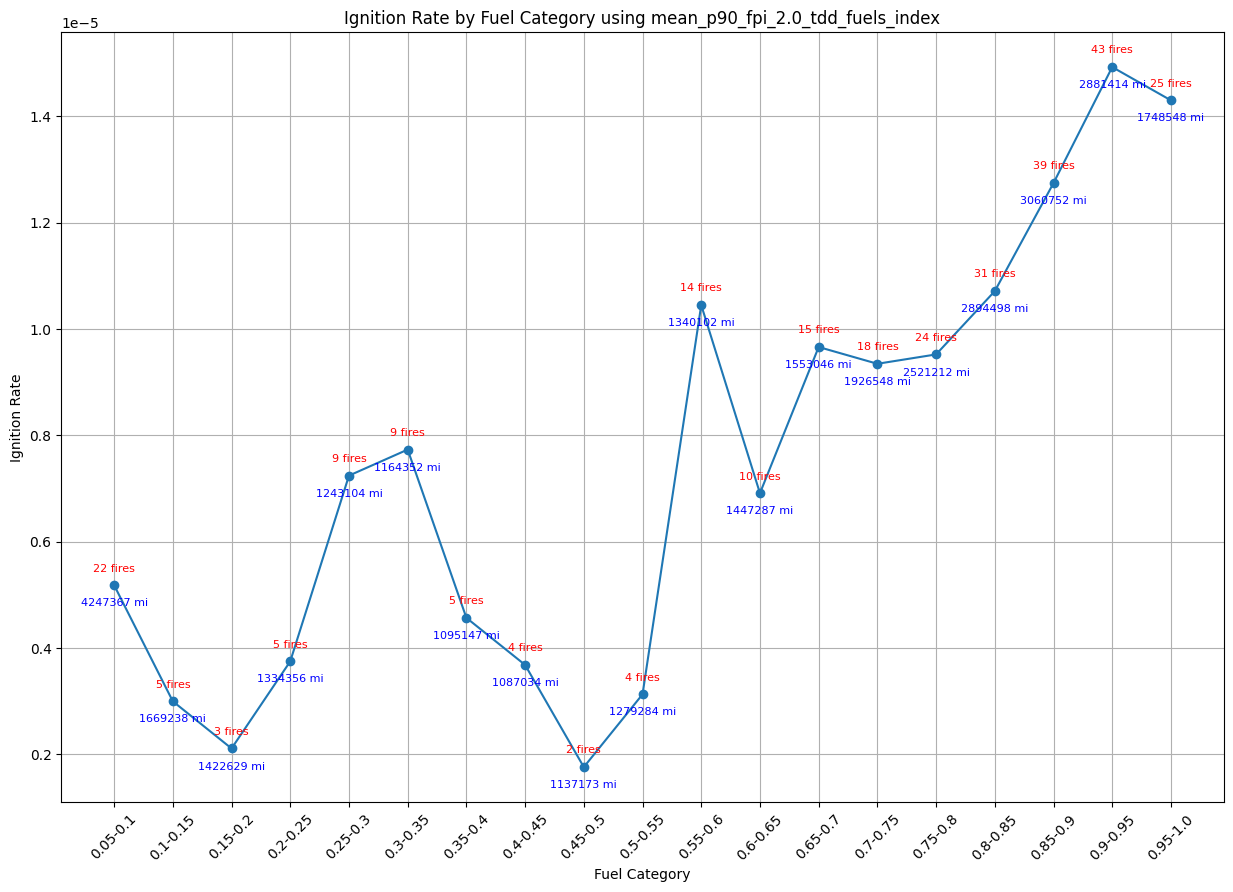

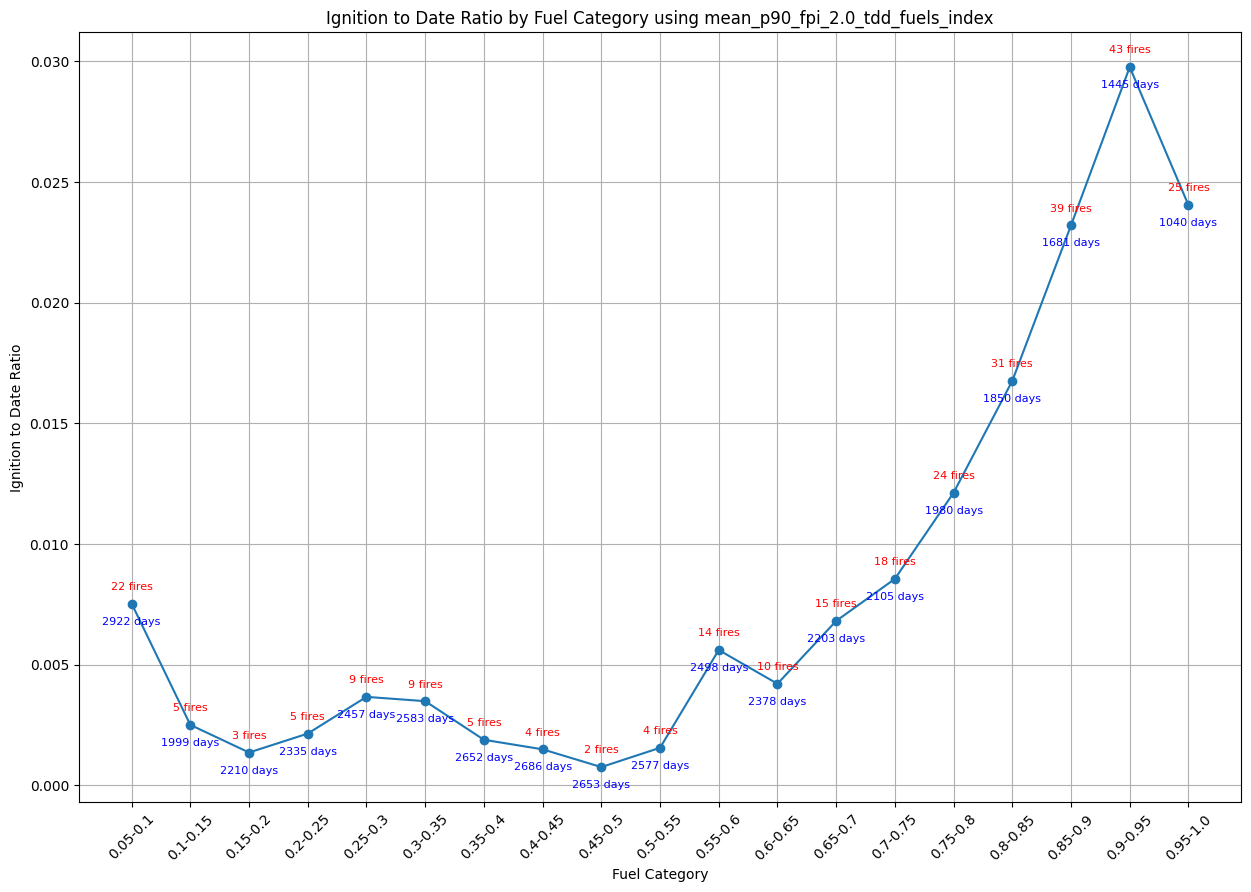

In [38]:
# create an aggregated copy of ignitions_agg and res_df2
ignitions_agg_agg = ignitions_agg.copy()
res_df2_agg = res_df2.copy()
# categorize fuel types
fuel_cutoff_list = [0.95, 0.9, 0.85, 0.8, 0.75, 0.7, 0.65, 0.6, 0.55, 0.5, 0.45, 0.4, 0.35, 0.3, 0.25, 0.2, 0.15, 0.10, 0.05,]
fuel_cutoff_choices = ["0.95-1.0"]
for i in range(1, len(fuel_cutoff_list)):
    fuel_cutoff_choices.append(f"{fuel_cutoff_list[i]}-{fuel_cutoff_list[i-1]}")
ignitions_agg_cond = [ignitions_agg_agg[f"{fuel_var}"] >= cutoff for cutoff in fuel_cutoff_list]
res_df2_agg_cond = [res_df2_agg[f"{fuel_var}"] >= cutoff for cutoff in fuel_cutoff_list]
ignitions_agg_agg['Fuel Category'] = np.select(ignitions_agg_cond, fuel_cutoff_choices, default=fuel_cutoff_choices[-1])
res_df2_agg['Fuel Category'] = np.select(res_df2_agg_cond, fuel_cutoff_choices, default=fuel_cutoff_choices[-1])
# keep only res_df2_agg with year between 2017 and 2024
res_df2_agg = res_df2_agg[pd.to_datetime(res_df2_agg['Date']).dt.year.between(2017, 2024)]
# # create a copy of the res_df2_agg, drop duplicates of Date and Fuel Category
# res_df2_agg_cp = res_df2_agg[['Date', 'Fuel Category']].drop_duplicates()

# create a temporary dataframe
fuel_cutoff_df = pd.DataFrame(fuel_cutoff_choices, columns=['Fuel Category'])
# group ignitions_agg_agg by Fuel Category, take sum of Ignition Count
ignitions_agg_grouped = ignitions_agg_agg.groupby('Fuel Category').agg({'Ignition_Count': 'sum'}).reset_index()
# group res_df2_agg by Fuel Category, take sum of Circuit Miles, unique count of Date
res_df2_agg_grouped = res_df2_agg.groupby('Fuel Category').agg({'Circuit Miles': 'sum', 'Date': 'nunique'}).reset_index()
# # group res_df2_agg_cp by Fuel Category, get unique count of Date
# res_df2_agg_grouped_date = res_df2_agg_cp.groupby('Fuel Category').agg({'Date': 'count'}).reset_index()
# merge res_df2_agg_grouped and res_df2_agg_grouped_date
# merge ignitions_agg_grouped and with fuel_cutoff_df and res_df2_agg_grouped
fuel_cutoff_df = pd.merge(fuel_cutoff_df, ignitions_agg_grouped, on='Fuel Category', how='outer')
fuel_cutoff_df = pd.merge(fuel_cutoff_df, res_df2_agg_grouped, on='Fuel Category', how='outer')
# fuel_cutoff_df = pd.merge(fuel_cutoff_df, res_df2_agg_grouped_date, on='Fuel Category', how='outer')
# for ignition count, fillna with 0
fuel_cutoff_df['Ignition_Count'] = fuel_cutoff_df['Ignition_Count'].fillna(0)
# calculate the rate
fuel_cutoff_df['Ignition Rate'] = fuel_cutoff_df['Ignition_Count'] / fuel_cutoff_df['Circuit Miles']
# calculation ignition to Date ratio
fuel_cutoff_df['Ignition to Date Ratio'] = fuel_cutoff_df['Ignition_Count'] / fuel_cutoff_df['Date']

# draw a line plot
fig, ax = plt.subplots(figsize=(15, 10))
ax.plot(fuel_cutoff_df['Fuel Category'], fuel_cutoff_df['Ignition Rate'], marker='o')
# annotate the points by ignition_count
for i, txt in enumerate(fuel_cutoff_df['Ignition Rate']):
    ax.annotate(f"{int(fuel_cutoff_df['Ignition_Count'][i])} fires", (fuel_cutoff_df['Fuel Category'][i], fuel_cutoff_df['Ignition Rate'][i]), textcoords="offset points", xytext=(0,10), ha='center', fontsize=8, color='red')
    # add Circuit Miles below the point
    ax.annotate(f"{int(fuel_cutoff_df['Circuit Miles'][i])} mi", (fuel_cutoff_df['Fuel Category'][i], fuel_cutoff_df['Ignition Rate'][i]), textcoords="offset points", xytext=(0,-15), ha='center', fontsize=8, color='blue')
ax.set_title(f'Ignition Rate by Fuel Category using {fuel_var}')
ax.set_xlabel('Fuel Category')
ax.set_ylabel('Ignition Rate')
plt.xticks(rotation=45)
plt.grid()
plt.show()

# draw another line plot for Ignition to Date Ratio
fig, ax = plt.subplots(figsize=(15, 10))
ax.plot(fuel_cutoff_df['Fuel Category'], fuel_cutoff_df['Ignition to Date Ratio'], marker='o')
# annotate the points by ignition_count
for i, txt in enumerate(fuel_cutoff_df['Ignition to Date Ratio']):
    ax.annotate(f"{int(fuel_cutoff_df['Ignition_Count'][i])} fires", (fuel_cutoff_df['Fuel Category'][i], fuel_cutoff_df['Ignition to Date Ratio'][i]), textcoords="offset points", xytext=(0,10), ha='center', fontsize=8, color='red')
    # add Date below the point
    ax.annotate(f"{int(fuel_cutoff_df['Date'][i])} days", (fuel_cutoff_df['Fuel Category'][i], fuel_cutoff_df['Ignition to Date Ratio'][i]), textcoords="offset points", xytext=(0,-15), ha='center', fontsize=8, color='blue')
ax.set_title(f'Ignition to Date Ratio by Fuel Category using {fuel_var}')
ax.set_xlabel('Fuel Category')
ax.set_ylabel('Ignition to Date Ratio')
plt.xticks(rotation=45)
plt.grid()
plt.show()